# Kildisiute et al. 2021 — Neuroblastoma · 02 Manifold

Fit the cell-state trajectory. The manifold is **non-branching** (single developmental axis), so we use scFates **`curve`** (not `tree`). The trajectory is **scoped to the Embryonic compartment** identified in 01 — the Cycling lobe confounds Gast with proliferation and does not reproduce the reference relationships. We do **not** re-embed the compartment (avoids folding a linear strip); the curve is fit on the existing joint UMAP and its edges are rendered to confirm it is fold-free.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load, scope to Embryonic compartment, graph-smooth scores

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
sub = adata[adata.obs['compartment']=='Embryonic'].copy()
print('scoped Embryonic compartment:', sub.shape[0], 'cells')
xy = sub.obsm['X_umap']; c0 = xy - xy.mean(0)
from numpy.linalg import svd; u,s,vt = svd(c0, full_matrices=False)
print(f'compartment UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}  (elongated -> linear)')
# rebuild neighbours on the scoped cells and graph-smooth signature scores for geography
sc.pp.neighbors(sub, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
A = (sub.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = sub.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): sub.obs[lab+'_sm'] = S[:,j]
print('smoothed spatial correlations on the Embryonic compartment:')
for a_,b_ in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a_} vs {b_}: r = {np.corrcoef(sub.obs[a_], sub.obs[b_])[0,1]:+.2f}')

whole malignant manifold: 1720 cells
scoped Embryonic compartment: 1504 cells
compartment UMAP aspect ratio (major/minor std): 1.46  (elongated -> linear)
smoothed spatial correlations on the Embryonic compartment:
  Gast_sm vs pSom_sm: r = +0.91
  Crest_sm vs Gast_sm: r = -0.66
  Crest_sm vs pSom_sm: r = -0.84


### Fit the principal curve — topology check (tips, forks, fold self-approach)
A fold-free curve has exactly 2 tips, 0 forks, and a self-approach ratio > 1 (no non-adjacent nodes come closer than an edge length). We confirm across a range of `Nodes` that the topology is a simple non-branching curve — `Nodes` derived here (not inherited): a low node count for ~1.5k cells keeps the curve from chasing local density.

In [4]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a_ in range(F.shape[0]):
        for b_ in range(a_+1, F.shape[0]):
            if G[a_,b_] >= 3: dmin = min(dmin, np.sqrt(((F[a_]-F[b_])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for Nodes in [15, 20, 30]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(sub, Nodes=Nodes, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(sub)
    print(f'Nodes={Nodes:>2}: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
# settle at Nodes=20 (fold-free, stable across the range)
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'committed curve: {tips} tips, {forks} forks, fold ratio {sa:.2f}')
assert forks == 0 and sa > 1, 'topology check failed'

Nodes=15: 2 tips, 0 forks | fold self-approach ratio = 2.98 (>1 = fold-free)
Nodes=20: 2 tips, 0 forks | fold self-approach ratio = 2.98 (>1 = fold-free)
Nodes=30: 2 tips, 0 forks | fold self-approach ratio = 2.35 (>1 = fold-free)
committed curve: 2 tips, 0 forks, fold ratio 2.98


### Root from developmental order (Gast/pSom-high tip), pseudotime
The root is the curve tip with the highest Gast+pSom and lowest Crest — the developmental origin. Crest (neural crest) is developmentally **late**, so it is never the root.

In [5]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low = developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, sub.obs[s_]); print(f'  {s_}: rho={rho:+.3f} p={p:.1e}')
print('-> Crest rises terminally; cell cycle only weakly tracks pseudotime (axis is developmental, not proliferative).')

tip 0: Gast=+0.1006 pSom=+0.1077 Crest=-0.0067
tip 2: Gast=+0.1044 pSom=+0.1226 Crest=-0.0228
derived root = tip 2 (Gast/pSom-high, Crest-low = developmental origin)
gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=-0.010 p=7.1e-01
  pSom_sm: rho=-0.255 p=8.4e-24
  Crest_sm: rho=+0.402 p=1.6e-59
  cyc_score: rho=+0.142 p=3.3e-08
-> Crest rises terminally; cell cycle only weakly tracks pseudotime (axis is developmental, not proliferative).


### House linear layout — orient pseudotime left -> right
Pseudotime runs along the UMAP y-axis here (near-vertical strip), so the layout transform swaps axes then flips x so low pseudotime is on the left. This matches the reference linear-trajectory panel orientation; direction is the only change (no re-embedding).

In [6]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
rx = abs(np.corrcoef(xy[:,0], t)[0,1]); ry = abs(np.corrcoef(xy[:,1], t)[0,1])
# put the pseudotime-aligned axis on x
if ry > rx: xyr = np.column_stack([xy[:,1], xy[:,0]])
else:       xyr = np.column_stack([xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0: xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: axis-swap + flip; corr(x_lin, pseudotime) = {r:+.2f}')

orientation: axis-swap + flip; corr(x_lin, pseudotime) = +0.98


### Render the fitted curve over the embedding (fold check) + save

curve rendered fold-free over the embedding (no W/U folds)


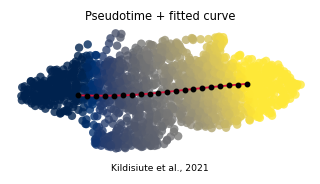

In [7]:
F = sub.uns['graph']['F'].T
# map node positions through the same linear-layout transform for the render
def lin(P):
    Q = np.column_stack([P[:,1], P[:,0]]) if ry>rx else P.copy()
    if (np.corrcoef(sub.obsm['X_umap'][:,1 if ry>rx else 0], t)[0,1]) < 0: Q[:,0] = -Q[:,0]
    return Q
Fl = lin(F); xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
ax.scatter(xl[:,0], xl[:,1], c=t, cmap='cividis', s=30, alpha=.8, linewidths=0)
B = np.asarray(sub.uns['graph']['B']); ii,jj = np.where(np.triu(B>0))
for i0,j0 in zip(ii,jj): ax.plot([Fl[i0,0],Fl[j0,0]],[Fl[i0,1],Fl[j0,1]],'-',color='crimson',lw=1.2)
ax.scatter(Fl[:,0],Fl[:,1],c='k',s=8,zorder=5)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py); ax.axis('off')
ax.set_title('Pseudotime + fitted curve', size=7.5)
ax.text(.5,-.12,'Kildisiute et al., 2021', ha='center', transform=ax.transAxes, size=6)
print('curve rendered fold-free over the embedding (no W/U folds)')

saved manifold.h5ad + manifold.pdf


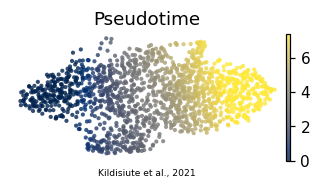

In [8]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Kildisiute et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')